# 07 · Evaluación final en el test (hold-out jul–dic 2012) — Sprint 4

**Responsable:** Joan · **Plan:** `project_plan_crisp_dm.md` §4.1, §8.1 y §8.2 · **Modelo:** el elegido en el Sprint 3 (fichas 20 y 21), **fijado antes de ver el test**.

**Protocolo (no se cambia después de ver los resultados):**
1. El modelo final es **LightGBM manual** con los hiperparámetros de la ficha 4 (`CONFIG["lgbm"]["params_tuneados"]`), objetivo `log1p` y `lag_24`, `lag_168`, `lag_336`; horizonte «día siguiente, pronóstico emitido a las 00:00».
2. Se reentrena **una vez** con todo train (2011-01-01 a 2012-06-30) y se predice el test **una vez**. Las predicciones se guardan y todo el análisis posterior (aquí y en el notebook 08) usa **esas mismas predicciones**.
3. Los demás modelos se evalúan en el test solo como **referencia de la tabla §8.1**; **no se usan para decidir nada** (la elección ya está hecha).
4. Si el resultado fuera malo, se reporta tal cual: no se vuelve a ajustar nada con el test.

**Leyenda:** ✅ verificado con el código de este notebook · 🔶 hipótesis · ⏳ pendiente.

## 1) Preparación

In [1]:
import sys, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from lightgbm import LGBMRegressor
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline

for _p in [Path.cwd(), *Path.cwd().parents]:
    if (_p / "config" / "config.py").exists():
        RAIZ = _p
        break
else:
    raise FileNotFoundError("No se encontró config/config.py")
sys.path.insert(0, str(RAIZ))

from config.config import CONFIG, RANDOM_STATE
from src.data_loader import load_data, temporal_split, separar_xy
from src.features import build_preprocessor, agregar_lags
from src.evaluate import ajustar, predecir_bicis, calcular_metricas, rmsle, get_cv, validar_temporal
from src.lineales import PrepLineal
from src.clustering import build_clustering, K_ELEGIDO

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
FIG_DIR = CONFIG["dir_reports"] / "joan" / "figuras"; FIG_DIR.mkdir(parents=True, exist_ok=True)
def guardar(fig, nombre): fig.savefig(FIG_DIR / f"{nombre}.png", dpi=130, bbox_inches="tight")

MF = CONFIG["modelo_final"]; LAGS = MF["lags"]
df = load_data()
df_l = agregar_lags(df, horas=MF["horas_lags"])
train_l, test_l = temporal_split(df_l)
X_tr, y_tr = separar_xy(train_l)
X_te, y_te = separar_xy(test_l)
y_tr, y_te = np.asarray(y_tr, float), np.asarray(y_te, float)
print("Train:", X_tr.shape, X_tr.index.min(), "->", X_tr.index.max())
print("Test :", X_te.shape, X_te.index.min(), "->", X_te.index.max(), "| horas ausentes excluidas:", int(test_l['cnt'].isna().sum()))
print("Modelo final:", MF["horizonte"], "| lags:", LAGS)

Train: (13003, 16) 2011-01-01 00:00:00 -> 2012-06-30 23:00:00
Test : (4376, 16) 2012-07-01 00:00:00 -> 2012-12-31 23:00:00 | horas ausentes excluidas: 40
Modelo final: día siguiente (24 h), pronóstico emitido a las 00:00 | lags: ('lag_24', 'lag_168', 'lag_336')


### ✅ Punto de control 1: separación train/test

In [2]:
assert X_tr.index.max() == pd.Timestamp("2012-06-30 23:00") and X_te.index.min() >= pd.Timestamp("2012-07-01")
assert X_tr.index.max() < X_te.index.min() and len(X_tr) == 13003
assert not ({"cnt", "casual", "registered", "instant"} & (set(X_tr.columns) | set(X_te.columns)))
# Los lags del test miran el pasado (puede ser train o test anterior): comprobación directa
t = X_te.index[500]
for h in MF["horas_lags"]:
    assert np.isclose(X_te.loc[t, f"lag_{h}"], df.loc[t - pd.Timedelta(hours=h), "cnt"], equal_nan=True)
print("✅ Train hasta 2012-06-30; test desde 2012-07-01; lags construidos solo con el pasado de cada hora.")

✅ Train hasta 2012-06-30; test desde 2012-07-01; lags construidos solo con el pasado de cada hora.


## 2) Reentrenamiento del modelo final con todo train
Misma configuración que en el Sprint 3: `build_preprocessor(lags=...)` + `LGBMRegressor` con los hiperparámetros de la ficha 4, ajustado sobre `log1p(cnt)`. **Todo el aprendizaje** (medianas, categorías, árboles) ocurre solo con train. Se guarda en `models/lgbm_final.joblib`, con el que `src/predict.py` hará la inferencia.

In [3]:
P_FINAL = {**CONFIG["lgbm"]["params_base"], **CONFIG["lgbm"]["params_tuneados"]}
def pipe_final(): return Pipeline([("prep", build_preprocessor(lags=LAGS)), ("modelo", LGBMRegressor(**P_FINAL))])

# Antes de tocar el test: el RMSLE de validación (solo train) que justificó la elección
pf_val, rs_val = validar_temporal(pipe_final(), X_tr, y_tr, "final (validación)", cv=get_cv(gap=CONFIG["lgbm"]["gap_con_lags"]))
print(f"Validación temporal (solo train): RMSLE {rs_val['rmsle_media']:.4f} ± {rs_val['rmsle_std']:.4f} | por fold:", pf_val["rmsle"].round(4).tolist())

t0 = time.perf_counter()
modelo = ajustar(pipe_final(), X_tr, y_tr, log_target=True)
t_fit = time.perf_counter() - t0
paquete = {"pipeline": modelo, "log_target": True, "lags": LAGS, "params": P_FINAL,
           "entrenado_con": {"desde": str(X_tr.index.min()), "hasta": str(X_tr.index.max()), "filas": int(len(X_tr))},
           "validacion_rmsle": {"media": rs_val["rmsle_media"], "std": rs_val["rmsle_std"]}, "horizonte": MF["horizonte"]}
joblib.dump(paquete, MF["ruta"])
recargado = joblib.load(MF["ruta"])
print(f"Entrenado en {t_fit:.1f} s con {len(X_tr)} filas. Guardado en {MF['ruta'].relative_to(RAIZ)} ({MF['ruta'].stat().st_size/1e6:.2f} MB)")

Validación temporal (solo train): RMSLE 0.3732 ± 0.0566 | por fold: [0.3902, 0.4311, 0.4117, 0.3412, 0.2916]


Entrenado en 0.7 s con 13003 filas. Guardado en models\lgbm_final.joblib (1.59 MB)


### ✅ Punto de control 2: el modelo guardado es el final y se recarga igual

In [4]:
assert abs(rs_val["rmsle_media"] - 0.3732) < 6e-4 and abs(rs_val["rmsle_std"] - 0.0566) < 6e-4, "la validación no coincide con la ficha 21"
assert np.allclose(predecir_bicis(modelo, X_tr.iloc[-300:], True), predecir_bicis(recargado["pipeline"], X_tr.iloc[-300:], True))
assert recargado["entrenado_con"]["hasta"] == "2012-06-30 23:00:00" and recargado["entrenado_con"]["filas"] == 13003
assert recargado["params"]["n_estimators"] == 524 and recargado["lags"] == ("lag_24", "lag_168", "lag_336")
print("✅ Validación 0.3732 ± 0.0566 (ficha 21), entrenado solo hasta 2012-06-30 y recarga idéntica.")

✅ Validación 0.3732 ± 0.0566 (ficha 21), entrenado solo hasta 2012-06-30 y recarga idéntica.


## 3) Evaluación en test (una sola vez)

In [5]:
pred_te = predecir_bicis(modelo, X_te, True)                  # ÚNICA predicción del modelo final sobre el test
met = calcular_metricas(y_te, pred_te)
pred_df = pd.DataFrame({"y": y_te, "pred": pred_te}, index=X_te.index)
pred_df.to_csv(CONFIG["dir_reports"] / "joan" / "test_predicciones.csv")
print(f"TEST — RMSLE = {met['rmsle']:.4f} | RMSE = {met['rmse']:.2f} | MAE = {met['mae']:.2f} | R² = {met['r2']:.4f}  ({len(y_te)} horas)")
print(f"Validación (solo train, media de 5 folds): RMSLE = {rs_val['rmsle_media']:.4f} ± {rs_val['rmsle_std']:.4f}")
print("Demanda media real en test:", round(float(y_te.mean()), 1), "| predicha:", round(float(pred_te.mean()), 1), "| sesgo medio (log, real − pred):", round(float(np.mean(np.log1p(y_te) - np.log1p(pred_te))), 4))

TEST — RMSLE = 0.3505 | RMSE = 69.99 | MAE = 43.11 | R² = 0.8985  (4376 horas)
Validación (solo train, media de 5 folds): RMSLE = 0.3732 ± 0.0566
Demanda media real en test: 254.1 | predicha: 231.2 | sesgo medio (log, real − pred): 0.0508


### ✅ Punto de control 3

In [6]:
assert len(pred_df) == 4376 and np.isfinite(pred_df.to_numpy()).all() and (pred_df["pred"] >= 0).all()
assert np.isclose(rmsle(pred_df["y"], pred_df["pred"]), met["rmsle"])
print("✅ 4 376 horas de test con predicción finita y no negativa; predicciones guardadas en reports/joan/test_predicciones.csv.")

✅ 4 376 horas de test con predicción finita y no negativa; predicciones guardadas en reports/joan/test_predicciones.csv.


**Interpretación.** El modelo final obtiene en el test **RMSLE 0.3505, RMSE 69.99, MAE 43.11 y R² 0.8985** (4 376 horas con registro de jul–dic 2012). El RMSLE es **menor** que el de la validación temporal (0.3732 ± 0.0566) y queda dentro del rango de los folds (0.2916–0.4311); no hay señal de sobreajuste a la validación. 🔶 Posibles razones (no probadas): el modelo ya conoce el nivel de 2012 (entrena con 18 meses), el test es de mayor demanda en verano y otoño (el RMSLE tiende a ser menor cuando hay más bicicletas) y no contiene un cambio de nivel como el de ene–mar de 2012, que dominaba el error de validación.

**Sesgo:** la demanda media real es 254.1 bicicletas/hora y la predicha 231.2 (9 % menos); en escala log el residuo medio es +0.0508 (subestima, pero menos que en validación: +0.11).

## 4) Tabla comparativa en test (§8.1) — referencia, no para decidir
Los otros modelos se entrenan con todo train con las configuraciones registradas en las fichas y se evalúan una vez en el test. **La elección del modelo final no cambia con estos resultados.** Dos vías: sin lags y con los tres lags (para que la comparación sea justa).

In [7]:
class MediaPorGrupo(BaseEstimator, RegressorMixin):
    def fit(self, X, y):
        d = pd.DataFrame({"hr": X["hr"].to_numpy(), "workingday": X["workingday"].to_numpy(), "y": np.asarray(y, float)})
        self.medias_ = d.groupby(["hr", "workingday"])["y"].mean(); self.media_global_ = float(d["y"].mean()); return self
    def predict(self, X):
        k = pd.MultiIndex.from_arrays([X["hr"].to_numpy(), X["workingday"].to_numpy()])
        return self.medias_.reindex(k).fillna(self.media_global_).to_numpy()

cfg_automl = json.load(open(CONFIG["dir_reports"] / "jose" / "automl_config.json", encoding="utf-8"))
def lgbm_flaml(c):
    c = dict(c); lmb = c.pop("log_max_bin"); return LGBMRegressor(max_bin=(1 << int(round(lmb))) - 1, n_jobs=-1, verbose=-1, **c)
P_RF = dict(n_estimators=300, max_features=0.5, min_samples_leaf=1, max_depth=25)

def construir(nombre, lags):
    lg = tuple(LAGS) if lags else ()
    if nombre == "Baseline (hr, workingday)": return MediaPorGrupo(), False
    if nombre == "Ridge (splines × temp)": return Pipeline([("prep", PrepLineal(codif_hora="splines", interaccion_temp=True, lags=lg)), ("modelo", Ridge(alpha=1.0))]), True
    if nombre == "Random Forest": return Pipeline([("prep", build_preprocessor(lags=lg)), ("modelo", RandomForestRegressor(n_jobs=-1, random_state=RANDOM_STATE, **P_RF))]), True
    if nombre == "LightGBM manual": return Pipeline([("prep", build_preprocessor(lags=lg)), ("modelo", LGBMRegressor(**P_FINAL))]), True
    if nombre == "AutoML (config sin lags)": return Pipeline([("prep", build_preprocessor(lags=lg)), ("modelo", lgbm_flaml(cfg_automl["sin_lags"]["mejor_config"]))]), True
    if nombre == "AutoML (config con lags)": return Pipeline([("prep", build_preprocessor(lags=lg)), ("modelo", lgbm_flaml(cfg_automl["con_lags"]["mejor_config"]))]), True
    raise ValueError(nombre)

filas = []; PRED_REF = {}
for via, lags, lista in [("Sin lags", False, ["Baseline (hr, workingday)", "Ridge (splines × temp)", "Random Forest", "LightGBM manual", "AutoML (config sin lags)"]),
                         ("3 lags (24, 168, 336)", True, ["Ridge (splines × temp)", "Random Forest", "LightGBM manual", "AutoML (config sin lags)", "AutoML (config con lags)"])]:
    for nombre in lista:
        pipe_, log_t = construir(nombre, lags)
        t0 = time.perf_counter(); m = ajustar(pipe_, X_tr, y_tr, log_t); tt = time.perf_counter() - t0
        p = predecir_bicis(m, X_te, log_t); PRED_REF[(via, nombre)] = p
        filas.append({"vía": via, "modelo": nombre + (" ← FINAL" if (via != "Sin lags" and nombre == "LightGBM manual") else ""), **calcular_metricas(y_te, p), "tiempo de ajuste (s)": tt})
tabla_test = pd.DataFrame(filas)
for via in tabla_test["vía"].unique():
    print(via); display(tabla_test[tabla_test["vía"] == via].drop(columns="vía").set_index("modelo").round(4))

Sin lags


,rmsle,rmse,mae,r2,tiempo de ajuste (s)
modelo,,,,,
"Baseline (hr, workingday)",0.5999,150.3489,107.2097,0.5316,0.0031
Ridge (splines × temp),0.3857,86.3890,51.5561,0.8454,0.0698
Random Forest,0.3812,78.9087,50.8665,0.8710,0.7476
LightGBM manual,0.3463,69.1745,43.8096,0.9009,0.5864
AutoML (config sin lags),0.3271,67.0166,42.6335,0.9069,0.7275


3 lags (24, 168, 336)


,rmsle,rmse,mae,r2,tiempo de ajuste (s)
modelo,,,,,
Ridge (splines × temp),0.3802,97.1162,57.1443,0.8046,0.1340
Random Forest,0.3795,77.6256,47.4727,0.8752,1.0282
LightGBM manual ← FINAL,0.3505,69.9896,43.1141,0.8985,0.6786
AutoML (config sin lags),0.3389,69.9992,43.3621,0.8985,0.6610
AutoML (config con lags),0.3506,72.3404,44.1886,0.8916,0.3227


### ✅ Punto de control 4: el modelo final de la tabla es el mismo de la sección 3

In [8]:
p_tab = PRED_REF[("3 lags (24, 168, 336)", "LightGBM manual")]
assert np.allclose(p_tab, pred_te, atol=1e-6), "el LightGBM de la tabla debe dar las mismas predicciones que el modelo guardado"
assert len(tabla_test) == 10 and np.isfinite(tabla_test.select_dtypes("number").to_numpy()).all()
print("✅ La fila del modelo final coincide con las predicciones de la sección 3 (misma configuración, mismo entrenamiento).")

✅ La fila del modelo final coincide con las predicciones de la sección 3 (misma configuración, mismo entrenamiento).


**Interpretación.**
- **El orden de las familias se mantiene:** baseline (0.5999) < Ridge (0.3857) ≈ Random Forest (0.3812) < LightGBM (0.3463) < AutoML (0.3271) sin lags; con lags, Ridge 0.3802, Random Forest 0.3795, LightGBM 0.3505 y AutoML 0.3389 / 0.3506. El modelo final reduce el RMSLE del baseline en un **41.6 %** (0.5999 → 0.3505; en validación fue 33 %).
- ⚠️ **Hallazgo que hay que reportar: los lags no mejoraron a LightGBM en el test.** LightGBM sin lags tiene RMSLE 0.3463 frente a 0.3505 del modelo final con los tres lags (1.2 % peor; RMSE 69.99 frente a 69.17, MAE 43.11 frente a 43.81). Con Ridge y Random Forest los lags ayudan muy poco (0.3857 → 0.3802 y 0.3812 → 0.3795) y con AutoML (config sin lags) empeoran (0.3271 → 0.3389). La sección 5 muestra que los lags ayudan en nov–dic y **empeoran jul–oct**.
- **Esto era el riesgo anticipado:** el Sprint 1 y el 3 advirtieron que ningún fold de validación cubría julio ni agosto y que los lags habían brillado en el fold 3 (cambio de nivel de ene–mar de 2012). En un periodo estable de verano esa ventaja no aparece. No es un fallo del código: el modelo final se comporta como una versión con los lags de un nivel que ya aprendió.
- **AutoML sin lags (0.3271) es el mejor del test** (6.7 % mejor que el final). **No se usa para cambiar el modelo final**: la elección se fijó con la validación antes de ver el test; cambiarla ahora sería elegir con el test y dejaría sin estimación honesta el rendimiento. Si Joan decide cambiarlo igualmente, debe documentarse que la elección usó el test y que ya no hay estimación independiente.
- **Tiempo:** todos ajustan en menos de 1.1 s con todo train; la diferencia está en la búsqueda de hiperparámetros, no en el entrenamiento.

## 5) RMSLE mensual en test (sesgo por tendencia, §4.1)

n horas cnt medio real cnt medio predicho Final (3 lags)         \
                                                              RMSLE  sesgo   
fecha_hora                                                                   
2012-07        744        273.665            243.134          0.333  0.082   
2012-08        744        288.310            264.900          0.243  0.058   
2012-09        720        303.574            275.620          0.290  0.055   
2012-10        708        280.849            251.036          0.308  0.084   
2012-11        718        212.624            200.006          0.412  0.023   
2012-12        742        166.729            153.408          0.466  0.004   

           LightGBM sin lags        Baseline         
                       RMSLE  sesgo    RMSLE  sesgo  
fecha_hora                                           
2012-07                0.269  0.048    0.554  0.469  
2012-08                0.242  0.085    0.578  0.507  
2012-09                0.262  0.084    0.620  0.525  
2012-10                0.324  0.150    0.591  0.426  
2012-11                0.416  0.119    0.488  0.141  
2012-12                0.492 -0.065    0.736 -0.191

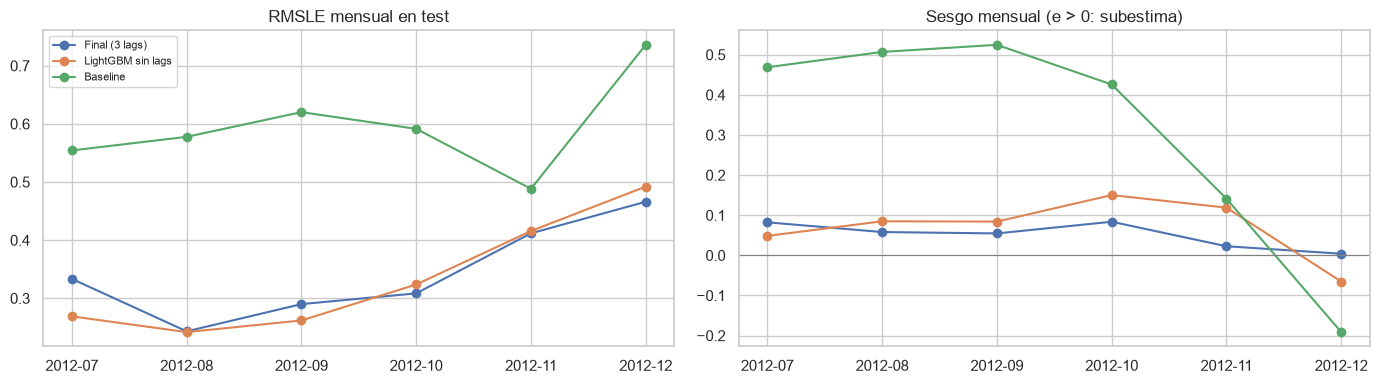

In [9]:
base_pred = PRED_REF[("Sin lags", "Baseline (hr, workingday)")]; sin_lags_pred = PRED_REF[("Sin lags", "LightGBM manual")]
def err(y, p): return np.log1p(y) - np.log1p(p)
e = {"Final (3 lags)": err(y_te, pred_te), "LightGBM sin lags": err(y_te, sin_lags_pred), "Baseline": err(y_te, base_pred)}
mes = pd.Series(X_te.index.to_period("M"), index=X_te.index)
mensual = pd.concat({k: pd.DataFrame({"RMSLE": pd.Series(v ** 2, index=X_te.index).groupby(mes).mean() ** 0.5, "sesgo": pd.Series(v, index=X_te.index).groupby(mes).mean()}) for k, v in e.items()}, axis=1)
mensual.insert(0, "n horas", pd.Series(1, index=X_te.index).groupby(mes).sum())
mensual.insert(1, "cnt medio real", pd.Series(y_te, index=X_te.index).groupby(mes).mean())
mensual.insert(2, "cnt medio predicho", pd.Series(pred_te, index=X_te.index).groupby(mes).mean())
display(mensual.round(3))
fig, ax = plt.subplots(1, 2, figsize=(14, 4)); meses = [str(m) for m in mensual.index]
for k in e: ax[0].plot(meses, mensual[(k, "RMSLE")], marker="o", label=k); ax[1].plot(meses, mensual[(k, "sesgo")], marker="o", label=k)
ax[0].set_title("RMSLE mensual en test"); ax[1].set_title("Sesgo mensual (e > 0: subestima)"); ax[1].axhline(0, color="gray", lw=0.8); ax[0].legend(fontsize=8)
plt.tight_layout(); guardar(fig, "18_test_rmsle_mensual"); plt.show()

### ✅ Punto de control 5

In [10]:
assert mensual.shape[0] == 6 and mensual["n horas"].sum() == 4376
assert np.isclose(np.sqrt((e["Final (3 lags)"] ** 2).mean()), met["rmsle"])
print("✅ 6 meses de test (jul–dic 2012), 4 376 horas; el RMSLE agrupado coincide con la sección 3.")

✅ 6 meses de test (jul–dic 2012), 4 376 horas; el RMSLE agrupado coincide con la sección 3.


**Interpretación.**
- **El error crece hacia fin de año:** RMSLE 0.333 (jul), 0.243 (ago), 0.290 (sep), 0.308 (oct), 0.412 (nov) y **0.466 (dic)**, el mes de menor demanda (cnt medio real 167). Coincide con lo visto: el RMSLE es mayor cuando hay pocas bicicletas.
- **No hay un sesgo por tendencia fuerte, pero sí subestimación en verano y otoño:** el sesgo (residuo medio en log) es +0.082 en julio, +0.058 en agosto, +0.055 en septiembre y +0.084 en octubre, y se acerca a 0 en nov–dic (+0.023 y +0.004). La demanda real supera a la predicha en 30 bicicletas en julio (273.7 frente a 243.1). 🔶 Es la subestimación que dejaba prever el crecimiento de 2012.
- **LightGBM sin lags** es mejor en jul–oct (0.269, 0.242, 0.262 y 0.324) y peor en dic (0.492 frente a 0.466): los lags mejoran los meses de invierno y empeoran los de verano en este test. Con lags el sesgo en jul–oct pasa de +0.048/+0.085/+0.084/+0.150 a +0.082/+0.058/+0.055/+0.084 (menos sesgo en ago–oct, más en julio), por lo que el empeoramiento del RMSLE no es solo de sesgo.
- **El baseline falla mucho más en verano y otoño** (sesgo de +0.43 a +0.53 entre jul y oct): su media por grupo viene de 2011 y H1 2012 y subestima demanda mucho mayor.

## 6) Dónde falla en test: hora, tipo de día, clima y cluster
Mismos cortes que en la validación (notebook 05), con las predicciones de la sección 3. Cluster = hipótesis de Pardo, ajustado con train.

Cortes de condición:


n  RMSLE  sesgo
corte      valor                    
workingday 0      1415  0.381  0.051
           1      2961  0.335  0.051
holiday    0      4233  0.335  0.055
           1       143  0.664 -0.088
adverso    0      4086  0.318  0.041
           1       290  0.654  0.182
cluster    0      1167  0.223  0.080
           1      1028  0.339  0.039
           2      1164  0.403  0.045
           3      1017  0.412  0.036

Horas con mayor RMSLE: {2: 0.52, 3: 0.457, 1: 0.427, 4: 0.407, 0: 0.402} | menor: {11: 0.233, 10: 0.251, 9: 0.262}
Por día de la semana (0 = domingo):


,n,RMSLE,sesgo
weekday,,,
0,648,0.349,0.060
1,624,0.400,0.080
2,610,0.374,0.039
3,624,0.402,0.007
4,622,0.286,0.029
5,624,0.308,0.067
6,624,0.318,0.073


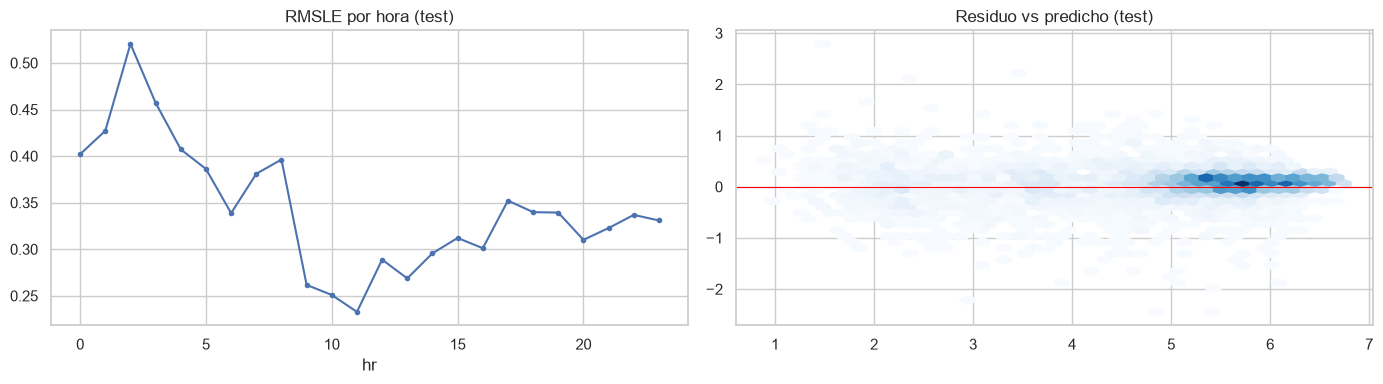

In [11]:
o = pred_df.copy(); o["e"] = err(o["y"].to_numpy(), o["pred"].to_numpy())
for c in ["hr", "workingday", "holiday", "weekday"]: o[c] = X_te[c]
o["adverso"] = X_te["weathersit"] >= 3
o["cluster"] = build_clustering(K_ELEGIDO).fit(X_tr).predict(X_te)
def por(col): g = o.groupby(col, observed=True)["e"]; return pd.DataFrame({"n": g.size(), "RMSLE": g.apply(lambda s: float(np.sqrt((s ** 2).mean()))), "sesgo": g.mean()})
cortes = {c: por(c) for c in ["workingday", "holiday", "adverso", "cluster"]}
print("Cortes de condición:"); display(pd.concat({k: v for k, v in cortes.items()}, names=["corte", "valor"]).round(3))
hr = por("hr"); print("Horas con mayor RMSLE:", hr["RMSLE"].sort_values(ascending=False).head(5).round(3).to_dict(), "| menor:", hr["RMSLE"].sort_values().head(3).round(3).to_dict())
print("Por día de la semana (0 = domingo):"); display(por("weekday").round(3))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(hr.index, hr["RMSLE"], marker="o", ms=3); ax[0].set_title("RMSLE por hora (test)"); ax[0].set_xlabel("hr")
ax[1].hexbin(np.log1p(o["pred"]), o["e"], gridsize=40, cmap="Blues", mincnt=1); ax[1].axhline(0, color="red", lw=0.8); ax[1].set_title("Residuo vs predicho (test)")
plt.tight_layout(); guardar(fig, "19_test_errores"); plt.show()

### ✅ Punto de control 6

In [12]:
assert cortes["adverso"]["n"].sum() == 4376 and cortes["cluster"]["n"].sum() == 4376
print("✅ Cortes completos. Horas con clima adverso en test:", int(cortes['adverso'].loc[True, 'n']), "| feriados:", int(cortes['holiday'].loc[1, 'n']))

✅ Cortes completos. Horas con clima adverso en test: 290 | feriados: 143


**Interpretación** (test, modelo final).
- **Clima adverso (`weathersit >= 3`, 290 horas):** RMSLE 0.654 frente a 0.318 con clima normal, y **subestimación marcada (+0.182)**. En validación el sesgo en lluvia era ≈ 0; aquí el modelo subestima la demanda en clima adverso. 🔶 Posible explicación: en estas horas el modelo confía en los lags (del mismo día de la semana anterior, probablemente con buen clima).
- **Feriados (143 horas):** RMSLE 0.664 frente a 0.335, con **sobreestimación** (−0.088): el modelo asume demanda de día laboral o de fin de semana normal y los feriados tienen menos demanda.
- **Tipo de día:** no laborables 0.381 frente a 0.335 en laborables (sesgo igual, +0.051).
- **Hora:** peor madrugada (2:00 = 0.520, 3:00 = 0.457, 1:00 = 0.427, 4:00 = 0.407, 0:00 = 0.402) y mejor media mañana (11:00 = 0.233, 10:00 = 0.251, 9:00 = 0.262): mismo patrón que en validación.
- **Día de la semana (0 = domingo):** jueves (0.402) y lunes (0.400) los peores, viernes (0.286) el mejor. Los lunes de test incluyen tres feriados (3-sep, 8-oct y 12-nov) y los jueves, el 22-nov (Acción de Gracias), y los feriados son el corte con más error.
- **Clusters (hipótesis de Pardo):** cluster 0 (tarde cálida y seca) 0.223, cluster 1 0.339, cluster 2 (no laborable) 0.403, cluster 3 (noche laborable) 0.412. El cluster 0 sigue siendo el más fácil; el 2 y el 3 son los más difíciles.

## 7) Evento Sandy (2012-10-29 y 30)
El 29-oct solo hay una hora registrada y el 30-oct, 11 (estructura vista en el EDA). Se compara lo registrado con lo predicho, como análisis descriptivo; **no se usa para ajustar nada**.

In [13]:
sandy = pred_df.loc["2012-10-28":"2012-10-31"].copy()
sandy["lag_24"] = X_te.loc[sandy.index, "lag_24"]; sandy["lag_168"] = X_te.loc[sandy.index, "lag_168"]; sandy["lag_336"] = X_te.loc[sandy.index, "lag_336"]
res = sandy.groupby(sandy.index.date).agg(horas=("y", "size"), real_total=("y", "sum"), pred_total=("pred", "sum"), lag24_ausente=("lag_24", lambda s: int(s.isna().sum())))
res["pred/real"] = res["pred_total"] / res["real_total"]
display(res.round(2))
print("Horas del 29 y 30 con registro:"); display(sandy.loc["2012-10-29":"2012-10-30", ["y", "pred"]].round(1))

,horas,real_total,pred_total,lag24_ausente,pred/real
2012-10-28,24,4459.0,4088.46,0,0.92
2012-10-29,1,22.0,16.96,0,0.77
2012-10-30,11,1096.0,1605.52,11,1.46
2012-10-31,24,5566.0,5335.77,13,0.96


Horas del 29 y 30 con registro:


,y,pred
fecha_hora,,
2012-10-29 00:00:00,22.0,17.0
2012-10-30 13:00:00,116.0,71.3
2012-10-30 14:00:00,126.0,69.0
2012-10-30 15:00:00,124.0,76.8
2012-10-30 16:00:00,98.0,100.1
2012-10-30 17:00:00,124.0,152.8
2012-10-30 18:00:00,143.0,167.6
2012-10-30 19:00:00,115.0,404.0
2012-10-30 20:00:00,81.0,208.1


### ✅ Punto de control 7

In [14]:
assert int(res.loc[pd.Timestamp("2012-10-29").date(), "horas"]) == 1
print("✅ El 29-oct tiene 1 sola hora registrada, como indica el plan (§3.4).")

✅ El 29-oct tiene 1 sola hora registrada, como indica el plan (§3.4).


**Interpretación.** Sandy confirma que el modelo no puede anticipar un evento sin precedente.
- **29-oct (1 hora registrada):** real 22 y predicho 17 (0.77 de lo observado).
- **30-oct (11 horas registradas, de 13:00 a 23:00):** real total 1 096 bicicletas y predicho **1 606 (1.46×)**. Sobreestima sobre todo a las **19:00 (real 115 frente a 404 predicho)**: ahí el modelo ve el patrón normal de un martes por la tarde (a través de `lag_168` y `lag_336`) sin saber que el sistema estaba casi detenido. En las 11 horas del 30-oct no hay `lag_24` (el día anterior casi no tiene datos), de modo que el modelo depende solo de los lags semanales.
- **31-oct (24 horas):** predicho 0.96 del real, aunque 13 horas no tienen `lag_24`: ya con operación normal el modelo se recupera.
- 🔶 Un modelo que depende de los lags hereda el comportamiento reciente: tras un evento extremo, los lags tardan días en reflejar la normalidad. No se ajusta nada con este análisis.

## 8) Resumen
Resultados reproducibles: el modelo, las predicciones del test (`reports/joan/test_predicciones.csv`) y las figuras 18 y 19 se generan con este notebook. La validación operativa (§8.4: ruido en el clima, backtest diario, métrica operativa, `predict.py`, casos límite y deriva) está en el notebook 08, que usa las mismas predicciones.